In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import sys
from pathlib import Path

src_path = Path().resolve().parents[1] / 'src'
if str(src_path) not in sys.path:
    sys.path.append(str(src_path))


from sciezka_projektu import get_project_root

PROJECT_ROOT = get_project_root()

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "Ruda Śląska"

df_rs_scada_weteran = pd.read_parquet(DATA_PATH / "scada-weteranow.parquet")
display(df_rs_scada_weteran)

df_rs_opady = pd.read_parquet(DATA_PATH / "suma_opadow.parquet")
display(df_rs_opady)


,Stempel,DataCzas,PoziomSciekow,PrzeplywSciekow,PradP1,PradP2,LicznikSciekow,IloscZalaczenP1,IloscZalaczenP2,CzasPracyP1,CzasPracyP2,PoziomMin,PoziomMax,PoziomOn,PoziomOff
0,1433288,2024-01-01 00:00:10,108,0,0,0,"599179,1",0,1,10722,10684,0,170,150,90
1,1433289,2024-01-01 00:00:30,112,0,0,0,"599179,1",0,1,10722,10684,0,170,150,90
2,1433290,2024-01-01 00:00:50,115,0,0,0,"599179,1",0,1,10722,10684,0,170,150,90
3,1433291,2024-01-01 00:01:10,115,0,0,0,"599179,1",0,1,10722,10684,0,170,150,90
4,1433292,2024-01-01 00:01:30,118,0,0,0,"599179,1",0,1,10722,10684,0,170,150,90
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4317920,5751208,2026-09-30 23:58:44,132,0,0,0,"815007,5",1,1,15850,15801,0,170,150,90
4317921,5751209,2026-09-30 23:59:04,132,0,0,0,"815007,5",1,1,15850,15801,0,170,150,90
4317922,5751210,2026-09-30 23:59:24,133,0,0,0,"815007,5",1,1,15850,15801,0,170,150,90
4317923,5751211,2026-09-30 23:59:44,134,0,0,0,"815007,5",1,1,15850,15801,0,170,150,90


,Data_czas,suma_opadu_mm
0,2024-01-01 00:00:00,0.0
1,2024-01-01 01:00:00,0.0
2,2024-01-01 02:00:00,0.0
3,2024-01-01 03:00:00,0.0
4,2024-01-01 04:00:00,0.0
...,...,...
24667,2026-10-24 20:00:00,0.0
24668,2026-10-24 21:00:00,0.0
24669,2026-10-24 22:00:00,0.0
24670,2026-10-24 23:00:00,0.0


In [2]:
from przepompowanie_ruda_dane import przygotuj_dane

X,y = przygotuj_dane()

In [3]:
%load_ext autoreload
%autoreload 2

train_end = int(len(X) * 0.7)

X_train = X.iloc[:train_end]
X_test = X.iloc[train_end:]

y_train = y.iloc[:train_end]
y_test = y.iloc[train_end:]

#print("TRAIN:", X_train.shape, X_train.index.min(), X_train.index.max())
#print("VAL:", X_val.shape, X_val.index.min(), X_val.index.max())
#print("TEST:", X_test.shape, X_test.index.min(), X_test.index.max())

In [4]:
# CATBOOST
from catboost import CatBoostRegressor

cb_median = CatBoostRegressor(
    loss_function = "MAE",
    iterations = 500,
    learning_rate = 0.05,
    depth = 5,
    random_seed=42,
    verbose=0
)
cb_median.fit(X_train, y_train)

cb_q97 = CatBoostRegressor(
    loss_function = "Quantile:alpha=0.97",
    iterations = 500,
    learning_rate = 0.05,
    depth = 5,
    random_seed=42,
    verbose=0
)
cb_q97.fit(X_train, y_train)

y_pred_val = cb_median.predict(X_test)
q_val = cb_q97.predict(X_test)

Godziny ponad normę: 152 z 7230


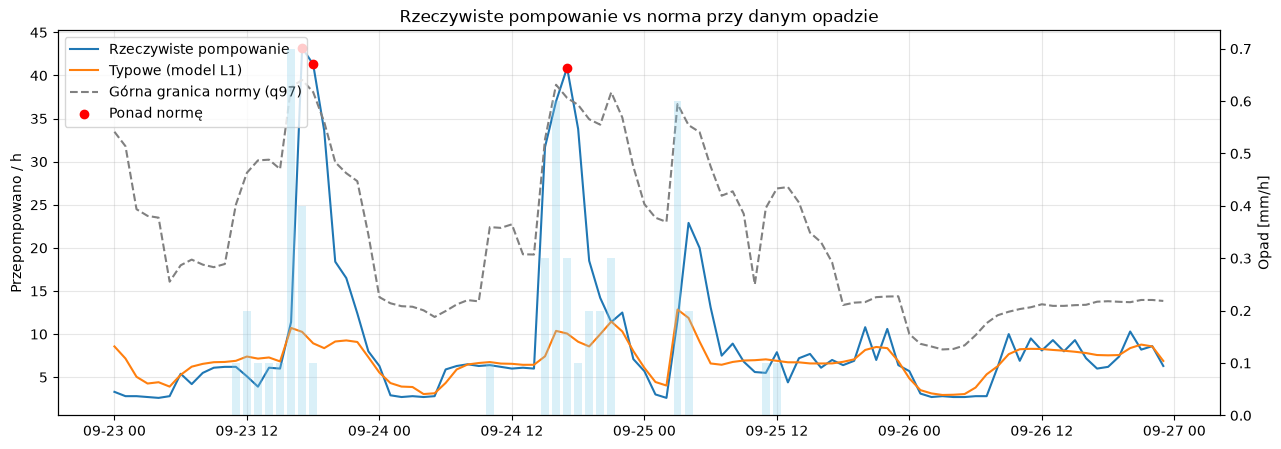

In [5]:
results_val = pd.DataFrame({
    "rzeczywiste": y_test,
    "prognoza": y_pred_val,
    "q97": q_val,
    "opad": X_test["opad_0h"],
    "opad_6h": X_test["opad_6h"],
}, index=y_test.index)

results_val["anomaly"] = results_val["rzeczywiste"] > results_val["q97"]
results_val["ponad_q97"] = (results_val["rzeczywiste"] - results_val["q97"]).clip(lower=0)

print("Godziny ponad normę:", int(results_val["anomaly"].sum()), "z", len(results_val))

sample = results_val.loc["2026-09-23":"2026-09-26"]
alarms = sample[sample["anomaly"]]

fig, ax1 = plt.subplots(figsize=(15, 5))
ax1.plot(sample.index, sample["rzeczywiste"], label="Rzeczywiste pompowanie")
ax1.plot(sample.index, sample["prognoza"], label="Typowe (model L1)")
ax1.plot(sample.index, sample["q97"], "--", color="gray", label="Górna granica normy (q97)")
ax1.scatter(alarms.index, alarms["rzeczywiste"], color="red", zorder=3, label="Ponad normę")
ax1.set_ylabel("Przepompowano / h")

ax2 = ax1.twinx()
ax2.bar(sample.index, sample["opad"], width=0.03, alpha=0.3, color="skyblue", label="Opad [mm/h]")
ax2.set_ylabel("Opad [mm/h]")

ax1.set_title("Rzeczywiste pompowanie vs norma przy danym opadzie")
ax1.legend(loc="upper left")
ax1.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.show()

In [6]:
# Alarm, gdy rzeczywiste pompowanie przekracza Q97
results_val["alarm"] = results_val["anomaly"]

# Nadwyżka względem typowej prognozy pogodowej
results_val["nadwyzka"] = (
    results_val["rzeczywiste"] - results_val["prognoza"]
).clip(lower=0)

print("Liczba godzin alarmowych:", results_val["alarm"].sum())

print(
    "Suma nadwyżek w godzinach alarmowych:",
    round(results_val.loc[results_val["alarm"], "nadwyzka"].sum(), 2)
)

Liczba godzin alarmowych: 152
Suma nadwyżek w godzinach alarmowych: 3486.33


In [7]:
anomalie = results_val[results_val["alarm"]].copy()

#kiedy wystąpiły alarmy, jaka była nadwyżka i czy padało
display(anomalie[["rzeczywiste", "prognoza", "q97", "nadwyzka", "ponad_q97", "opad", "opad_6h"]])

,rzeczywiste,prognoza,q97,nadwyzka,ponad_q97,opad,opad_6h
Data_czas,,,,,,,
2025-12-07 13:00:00,15.1,10.915177,14.732327,4.184823,0.367673,0.0,0.0
2025-12-11 04:00:00,19.1,5.178296,16.842534,13.921704,2.257466,0.1,0.1
2026-01-10 16:00:00,17.0,9.945672,15.108836,7.054328,1.891164,0.0,0.0
2026-01-26 07:00:00,30.8,10.488903,29.164649,20.311097,1.635351,0.2,0.8
2026-02-07 21:00:00,40.5,14.494717,25.369892,26.005283,15.130108,0.1,0.6
...,...,...,...,...,...,...,...
2026-09-21 18:00:00,39.0,11.104409,35.080623,27.895591,3.919377,0.1,4.1
2026-09-22 16:00:00,40.5,16.390842,39.590134,24.109158,0.909866,0.1,2.0
2026-09-23 17:00:00,43.2,10.257436,39.478996,32.942564,3.721004,0.4,1.6


In [8]:
from sklearn.metrics import mean_absolute_error
# Ewaluacja na zbiorze testowym
y_pred_test = cb_median.predict(X_test)
q_test = cb_q97.predict(X_test)

mae_test = mean_absolute_error(y_test, y_pred_test)
odsetek_test = (y_test > q_test).mean() * 100

print("MAE TEST:", round(mae_test, 2))
prof = y_train.groupby(y_train.index.hour).median()
base_test = prof.reindex(y_test.index.hour).values
print("MAE baseline:", round(mean_absolute_error(y_test, base_test), 2))
print("Przekroczenia Q97 TEST:", round(odsetek_test, 2), "%")
print("Liczba alarmów TEST:", int((y_test > q_test).sum()))


MAE TEST: 2.88
MAE baseline: 2.95
Przekroczenia Q97 TEST: 2.1 %
Liczba alarmów TEST: 152


In [9]:
#SHAP
import os
from SHAP import generate_shap_from_tree

C:\Users\Tomek\Desktop\Smart_Water_Challenge_2026\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


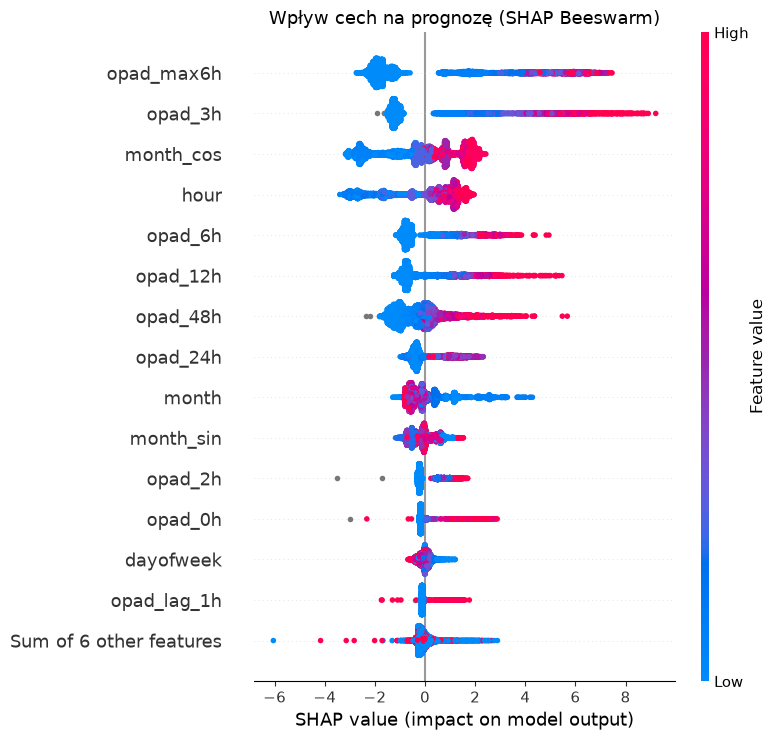

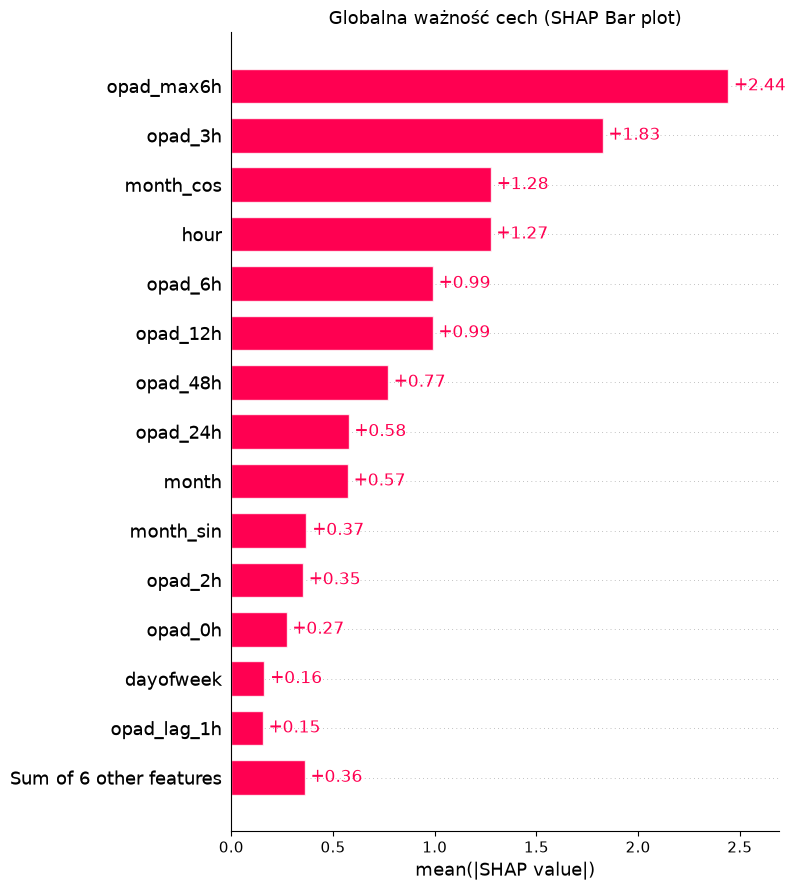

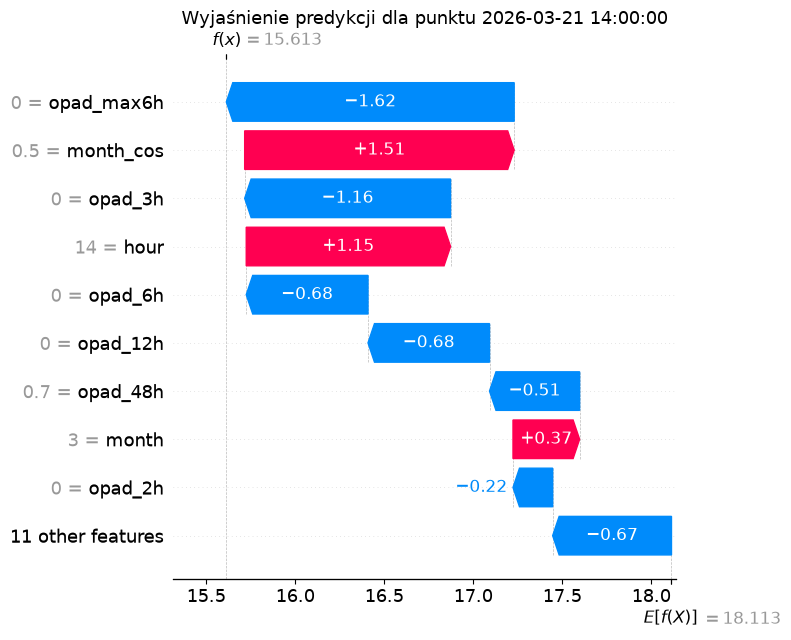

In [10]:
generate_shap_from_tree(cb_q97,X_test,date_with_time="2026-03-21 14:00:00")

# OPTYMALIZACJA OPTUNA

In [11]:
import numpy as np
import optuna
from lightgbm import LGBMRegressor, early_stopping, log_evaluation

train_end = int(len(X) * 0.7)
val_end = int(len(X) * 0.85)

X_train = X.iloc[:train_end]
X_val = X.iloc[train_end:val_end]
X_test = X.iloc[val_end:]

y_train = y.iloc[:train_end]
y_val = y.iloc[train_end:val_end]
y_test = y.iloc[val_end:]

import numpy as np
import optuna
from catboost import CatBoostRegressor

# STROJENIE MODELU MEDIANOWEGO (cb_median)
def objective_median(trial):
    params = {
        'loss_function': 'MAE',
        'eval_metric': 'MAE',
        'iterations': 1500,
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'depth': trial.suggest_int('depth', 4, 8),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1.0, 20.0),
        'random_strength': trial.suggest_float('random_strength', 1e-3, 5.0),
        'task_type': 'CPU',
        'random_seed': 42,
        'verbose': 0
    }

    model = CatBoostRegressor(**params, early_stopping_rounds=40)
    model.fit(X_train, y_train, eval_set=(X_val, y_val), use_best_model=True)

    preds = model.predict(X_val)
    mae = np.mean(np.abs(y_val - preds))
    return mae

study_median = optuna.create_study(direction="minimize")
study_median.optimize(objective_median, n_trials=40)
print("Najlepsze parametry dla Median:", study_median.best_params)


# STROJENIE MODELU KWANTYLOWEGO (cb_q97)
def pinball_loss(y_true, y_pred, alpha=0.97):
    err = y_true - y_pred
    return np.mean(np.maximum(alpha * err, (alpha - 1.0) * err))

def objective_q97(trial):
    params = {
        'loss_function': 'Quantile:alpha=0.97',
        'eval_metric': 'Quantile:alpha=0.97',
        'iterations': 1500,
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'depth': trial.suggest_int('depth', 4, 8),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1.0, 20.0),
        'random_strength': trial.suggest_float('random_strength', 1e-3, 5.0),
        'task_type': 'CPU',
        'random_seed': 42,
        'verbose': 0
    }

    model = CatBoostRegressor(**params, early_stopping_rounds=40)
    model.fit(X_train, y_train, eval_set=(X_val, y_val), use_best_model=True)

    q_preds = model.predict(X_val)

    #Błąd Pinball
    loss = pinball_loss(y_val, q_preds, alpha=0.97)

    #Kara za uciekanie od Coverage = 97%
    empirical_coverage = np.mean(y_val <= q_preds)
    coverage_penalty = np.abs(empirical_coverage - 0.97) * 5.0

    return loss + coverage_penalty

study_q97 = optuna.create_study(direction="minimize")
study_q97.optimize(objective_q97, n_trials=40)
print("Najlepsze parametry dla Q97:", study_q97.best_params)

[I 2026-10-27 18:37:31,518] A new study created in memory with name: no-name-2977bc54-117b-4689-bf1f-713fbb6f6ec6
[I 2026-10-27 18:37:31,699] Trial 0 finished with value: 2.336526737270645 and parameters: {'learning_rate': 0.033316894264860404, 'depth': 5, 'l2_leaf_reg': 8.168857787069847, 'random_strength': 0.11868386508189568}. Best is trial 0 with value: 2.336526737270645.
[I 2026-10-27 18:37:31,899] Trial 1 finished with value: 2.339481858064859 and parameters: {'learning_rate': 0.026149334012996506, 'depth': 5, 'l2_leaf_reg': 8.890430072112988, 'random_strength': 0.8770006440584147}. Best is trial 0 with value: 2.336526737270645.
[I 2026-10-27 18:37:32,130] Trial 2 finished with value: 2.3422054063269844 and parameters: {'learning_rate': 0.02672241395494182, 'depth': 6, 'l2_leaf_reg': 14.344974203812413, 'random_strength': 0.7482336912881835}. Best is trial 0 with value: 2.336526737270645.
[I 2026-10-27 18:37:32,315] Trial 3 finished with value: 2.352192097184656 and parameters: {

Najlepsze parametry dla Median: {'learning_rate': 0.03707109848547523, 'depth': 4, 'l2_leaf_reg': 2.6189752967638804, 'random_strength': 0.9383200576163983}


[I 2026-10-27 18:37:40,469] Trial 0 finished with value: 0.4460633121217759 and parameters: {'learning_rate': 0.029610598286399777, 'depth': 6, 'l2_leaf_reg': 12.581901666154746, 'random_strength': 1.1166409256392726}. Best is trial 0 with value: 0.4460633121217759.
[I 2026-10-27 18:37:43,446] Trial 1 finished with value: 0.45579038876471667 and parameters: {'learning_rate': 0.020146496229950545, 'depth': 4, 'l2_leaf_reg': 12.95521070141889, 'random_strength': 2.8688873249514217}. Best is trial 0 with value: 0.4460633121217759.
[I 2026-10-27 18:37:45,568] Trial 2 finished with value: 0.46163390737473975 and parameters: {'learning_rate': 0.01582523031203299, 'depth': 4, 'l2_leaf_reg': 9.428397279894098, 'random_strength': 4.467014615110478}. Best is trial 0 with value: 0.4460633121217759.
[I 2026-10-27 18:37:48,293] Trial 3 finished with value: 0.446461342351539 and parameters: {'learning_rate': 0.03669152210210674, 'depth': 7, 'l2_leaf_reg': 1.5064308058715197, 'random_strength': 2.769

Najlepsze parametry dla Q97: {'learning_rate': 0.02094487425738646, 'depth': 8, 'l2_leaf_reg': 16.323444426796154, 'random_strength': 2.019641509305754}


In [13]:
print("Najlepszy wynik median (MAE):", study_median.best_value)
print("Najlepsze parametry median:", study_median.best_params)

print("Najlepszy wynik q97 (MAE):", study_q97.best_value)
print("Najlepsze parametry q97:", study_q97.best_params)

Najlepszy wynik median (MAE): 2.3287974468116017
Najlepsze parametry median: {'learning_rate': 0.03707109848547523, 'depth': 4, 'l2_leaf_reg': 2.6189752967638804, 'random_strength': 0.9383200576163983}
Najlepszy wynik q97 (MAE): 0.42565108674631924
Najlepsze parametry q97: {'learning_rate': 0.02094487425738646, 'depth': 8, 'l2_leaf_reg': 16.323444426796154, 'random_strength': 2.019641509305754}


In [14]:
# CATBOOST
from catboost import CatBoostRegressor


check_median = CatBoostRegressor(
    **study_median.best_params,
    loss_function="MAE",
    eval_metric="MAE",
    iterations=2500,
    early_stopping_rounds=50,
    task_type="CPU",
    thread_count=-1,
    random_seed=42,
    verbose=100
)
check_median.fit(
    X_train, y_train,
    eval_set=(X_val, y_val),
    use_best_model=True
)


best_trees = check_median.get_best_iteration()
print(f"Optymalna liczba iteracji: {best_trees}")

0:	learn: 4.5347044	test: 2.5918284	best: 2.5918284 (0)	total: 2ms	remaining: 5s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 2.328796447
bestIteration = 22

Shrink model to first 23 iterations.
Optymalna liczba iteracji: 22


In [15]:
from catboost import CatBoostRegressor


check_q97 = CatBoostRegressor(
    **study_q97.best_params,
    loss_function="Quantile:alpha=0.97",
    eval_metric="Quantile:alpha=0.97",
    iterations=2500,
    early_stopping_rounds=50,
    task_type="CPU",
    thread_count=-1,
    random_seed=42,
    verbose=0
)

check_q97.fit(
    X_train, y_train,
    eval_set=(X_val, y_val),
    use_best_model=True)

best_trees_q97 = check_q97.get_best_iteration()
print(f"Optymalna liczba iteracji dla q97 to: {best_trees_q97}")

Optymalna liczba iteracji dla q97 to: 1475
